# PMITC v1.1 quick start
Load, join, plot one case. Labels are allegations by named sources ("flagged by <source>"), not findings; tables hold no personal names.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
DATA = '../data'
cases = pd.read_parquet(f'{DATA}/cases.parquet')
wallets = pd.read_parquet(f'{DATA}/wallets.parquet')
markets = pd.read_parquet(f'{DATA}/markets.parquet')
cases[['case_id','case_grade','investigation_outcome','n_documented_by_case','benchmark_split']].sort_values('n_documented_by_case', ascending=False).head(10)

,case_id,case_grade,investigation_outcome,n_documented_by_case,benchmark_split
60,us-iran-strike-2026-02-28,E4,unresolved,52,train
28,kpmg-earnings-2025-26,E4,unresolved,22,test
65,zachxbt-axiom-2026-02,E4,unresolved,10,train
34,nobel-peace-2025,E3,under_investigation,8,train
29,maduro-2026-01,E2,charged,7,train
58,us-iran-ceasefire-2026-04-07,E3,under_investigation,4,test
63,world-cup-2026-06,E4,unresolved,3,test
3,biden-pardons,E4,unresolved,2,test
5,bubblemaps-military-cluster,E4,unresolved,2,test
62,walz-vp-2024,E5,unresolved,1,train


In [2]:
# the three nested label sets (PROTOCOL A20)
wallets[['label_strict','label_standard','label_broad']].sum()

label_strict       19
label_standard    112
label_broad       119
dtype: Int64

In [3]:
# join: documented wallets -> their pre-news positions in their case markets (precise news time)
pos = pd.read_parquet(f'{DATA}/positions.parquet', filters=[('market_set','==','case'), ('t_news_version','==','precise'), ('label_strict','==',True)])
pos.merge(markets[['case_id','condition_id','question']], on=['case_id','condition_id'])[['case_id','question','wallet','buy_usdc_pre','vwap_price_usdc_pre','account_age_days_at_first_buy']].head(10)

,case_id,question,wallet,buy_usdc_pre,vwap_price_usdc_pre,account_age_days_at_first_buy
0,bubblemaps-military-cluster,"US strikes Iran by February 27, 2026?",0x09d3273fa76282ce09f4f35a87d6f087c05f4e84,1283.237288,0.150000,1.939144
1,bubblemaps-military-cluster,"US strikes Iran by February 28, 2026?",0x09d3273fa76282ce09f4f35a87d6f087c05f4e84,40541.311429,0.120032,0.339444
2,bubblemaps-military-cluster,"US strikes Iran by February 20, 2026?",0x09d3273fa76282ce09f4f35a87d6f087c05f4e84,4729.679153,0.117727,2.893206
3,bubblemaps-military-cluster,"US strikes Iran by February 20, 2026?",0x09d3273fa76282ce09f4f35a87d6f087c05f4e84,13100.118310,0.914126,2.916863
4,google-yis-2025,Will Andy Byron rank in Google’s Top 5 Most Se...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,6829.570613,0.868495,564.936586
5,google-yis-2025,Will Bianca Censori rank in Google’s Top 5 Mos...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,9508.349793,0.293095,527.067488
6,google-yis-2025,Will Kendrick Lamar be the #1 searched person ...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,9956.258433,0.088786,518.450451
7,google-yis-2025,Will Bianca Censori be the #1 searched person ...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,296064.192233,0.849996,529.980417
8,google-yis-2025,Will Donald Trump rank in Google’s Top 5 Most ...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,165777.082509,0.662669,538.937407
9,google-yis-2025,Will Donald Trump be the #1 searched person on...,0xee50a31c3f5a7c77824b12a941a54388a2827ed6,742.741000,0.202589,518.104907


Text(0.5, 1.0, 'Will Axiom be accused of insider trading?')

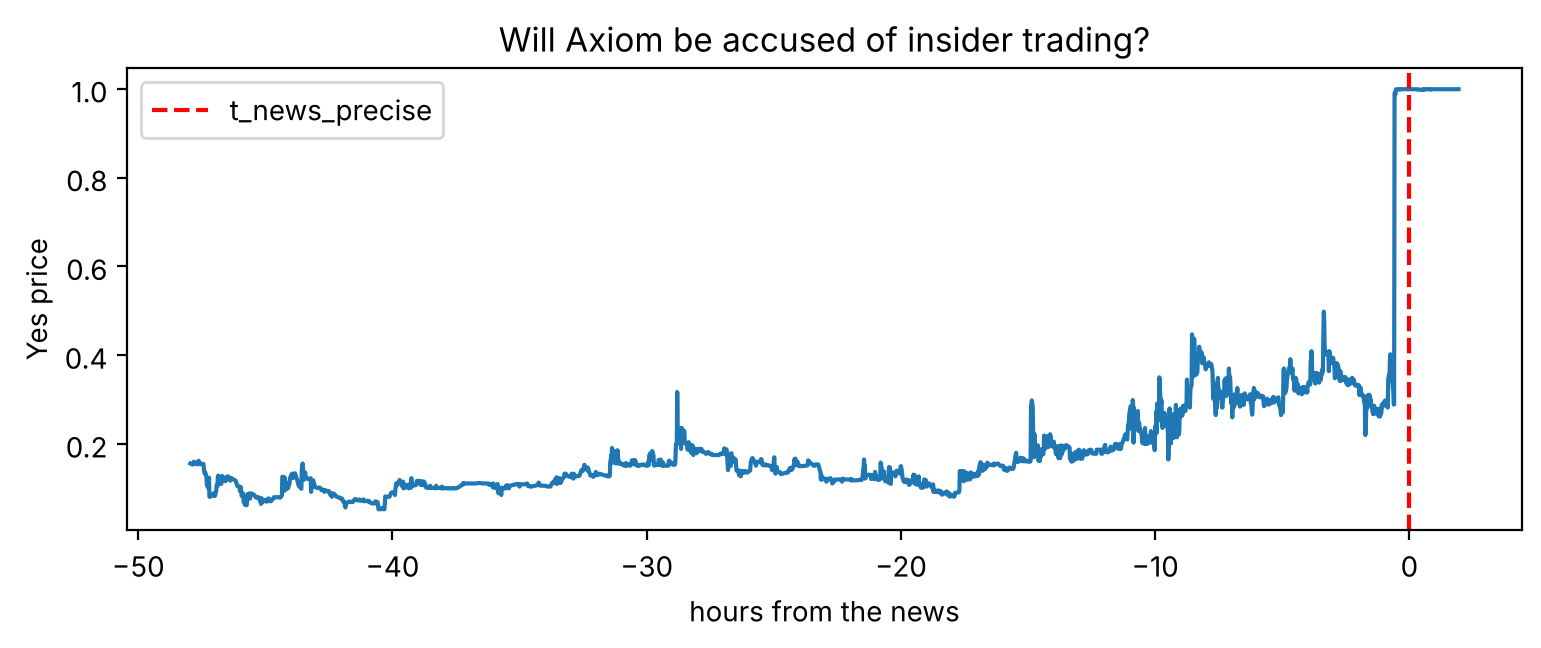

In [4]:
CASE = 'zachxbt-axiom-2026-02'
mm = pd.read_parquet(f'{DATA}/market_minutes.parquet', filters=[('case_id','==',CASE), ('market_set','==','case'), ('t_news_version','==','precise')])
cid = mm.groupby('condition_id').usdc.sum().idxmax()
g = mm[mm.condition_id == cid]
fig, ax = plt.subplots(figsize=(9,3)); ax.plot(g.minutes_from_cut / 60, g.last_price_usdc); ax.axvline(0, color='r', ls='--', label='t_news_precise')
ax.set_xlabel('hours from the news'); ax.set_ylabel('Yes price'); ax.legend(); ax.set_title(markets.set_index(['case_id','condition_id']).loc[(CASE, cid), 'question'])